# FF-VUS

## Setup

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from matplotlib.gridspec import GridSpec
from itertools import combinations

from tqdm import tqdm
from tqdm.notebook import tqdm_notebook
tqdm_notebook.pandas()

experiments_path = os.path.join('..', '..', 'experiments')
save_fig_path = os.path.join(experiments_path, 'figures')
os.makedirs(save_fig_path, exist_ok=True)

In [2]:
# Consistent color palette
color_palette = {
    'FF-VUS (L: 128)': '#c8b400',          # Good
    'FF-VUS-GPU (L: 128)': '#40da70',     # Very Good
    'FF-VUS': '#c8b400',          # Good
    'FF-VUS-GPU': '#40da70',     # Very Good
    'AUC': '#f1a73f',                # Secondary competitor
    'VUS (L: 128)': '#b02a41',            # Main competitor
    'AFFILIATION': '#A5D1C2',        # Useless competitors
    'Range-AUC (L: 128)': '#547C6E',       # Useless competitors
    'RF': '#123327',                    # Useless competitors
}

# Map shorthand names to formal names
formal_names = {
    'FF-VUS': 'FF-VUS (L: 128)',
    'FF-VUS-GPU': 'FF-VUS-GPU (L: 128)',
    'AUC': 'AUC',
    'VUS': 'VUS (L: 128)',
    'RF': 'RF',
    'AFFILIATION': 'AFFILIATION',
    'RANGE-AUC': 'Range-AUC (L: 128)',
    'auc': 'AUC',
    'vus': 'VUS (L: 128)',
    'ffvus': 'FF-VUS (L: 128)',
    'ffvusgpu': 'FF-VUS-GPU (L: 128)',
}

# Default seaborn style
sns.set_style("whitegrid")

In [3]:
def finalize_plot(save_dir, filename):
    plt.tight_layout()
    if filename is not None:
        save_path = os.path.join(save_dir, filename)
        # plt.savefig(f"{save_path}.svg", bbox_inches='tight')
        plt.savefig(f"{save_path}.pdf", bbox_inches='tight', pad_inches=0)
    plt.show()

def load_results(path):
    result_files = [file for file in os.listdir(path) if file.endswith('.csv')]

    df = pd.DataFrame()
    for file in tqdm(result_files):
        file_path = os.path.join(path, file)
        curr_df = pd.read_csv(file_path, index_col=0).reset_index()
        df = pd.concat([df, curr_df], ignore_index=True)
    return df


## Experiment 1: All metrics with default parameters on the TSB-UAD benchmark

In [4]:
curr_experiment_path = os.path.join(experiments_path, 'allmetrics_defparams_tsb', 'results')
df = load_results(curr_experiment_path)    
df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 7/7 [00:00<00:00, 82.70it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Metric,Metric value,Metric time,Existence,Step,...,Anomaly coordinates time,Safe mask time,Thresholds time,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time
2264,OPPORTUNITY/S3-ADL4.test.csv@81.out,27540,2,1080.000000,128.0,VUS (L: 128),0.570742,0.423863,True,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2959,YAHOO/Yahoo_A2synthetic_8_data.out,1420,3,3.000000,128.0,VUS (L: 128),0.292843,0.338283,True,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
66,ECG/MBA_ECG14046_data_28.out,229899,78,77.512821,128.0,Range-AUC (L: 128),0.042836,0.164101,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Runtime Box plots

In [5]:
# Average speed-ups compared to VUS
metric_to_compare = 'VUS (L: 128)'
speed_up_dict = {}

df_vus = df[df['Metric'] == metric_to_compare].set_index('Time series')
for metric in df['Metric'].unique():
    curr_df = df[df['Metric'] == metric].set_index('Time series')

    common_index = df_vus.index.intersection(curr_df.index)
    curr_speed_up = df_vus.loc[common_index, 'Metric time'] / curr_df.loc[common_index, 'Metric time']
    speed_up_dict[metric] = curr_speed_up.mean()
    print(f"{metric}: {speed_up_dict[metric]:.2f}x speed up")

Range-AUC (L: 128): 58.31x speed up
VUS (L: 128): 1.00x speed up
AFFILIATION: 128.03x speed up
AUC: 480.69x speed up
RF: 17.24x speed up
FF-VUS (L: 128): 110.71x speed up
FF-VUS-GPU (L: 128): 467.44x speed up


In [6]:
# Error of FF-VUS and FF-VUS-GPU compared to VUS
current_metrics = ['FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)']
vus_df = df[df['Metric'] == 'VUS (L: 128)'].set_index('Time series')

values_df = df[df['Metric'].isin(current_metrics)][['Time series', 'Metric', 'Metric value']]
values_df = values_df.pivot(columns='Metric', index='Time series', values='Metric value')
dif_df = values_df.apply(lambda row: row - vus_df.loc[row.name]['Metric value'], axis=1).abs()
dif_df.head(3)

Metric,FF-VUS (L: 128),FF-VUS-GPU (L: 128)
Time series,,
Daphnet/S01R02E0.test.csv@1.out,0.0,1.677621e-08
Daphnet/S01R02E0.test.csv@4.out,0.0,7.568250e-07
Daphnet/S01R02E0.test.csv@6.out,0.0,5.137035e-08


In [7]:
# Average time per time series
for metric in df['Metric'].unique():
    mean_per_ts = df[df['Metric'] == metric]['Metric time'].mean()

    print(f"{metric}: {mean_per_ts:.6f} secs per ts")

Range-AUC (L: 128): 0.050070 secs per ts
VUS (L: 128): 3.126450 secs per ts
AFFILIATION: 0.034216 secs per ts
AUC: 0.005249 secs per ts
RF: 0.362132 secs per ts
FF-VUS (L: 128): 0.037790 secs per ts
FF-VUS-GPU (L: 128): 0.003939 secs per ts


In [8]:
# We use it at experiment 3
df_auc = df[df['Metric'] == 'AUC']

/tmp/ipykernel_7625/2724871926.py:35: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  axis.set_ylim(0, 80)


FF-VUS-GPU (L: 128) => max error: 4e-03, mean error: 3e-05
FF-VUS (L: 128) => max error: 1e-15, mean error: 7e-17


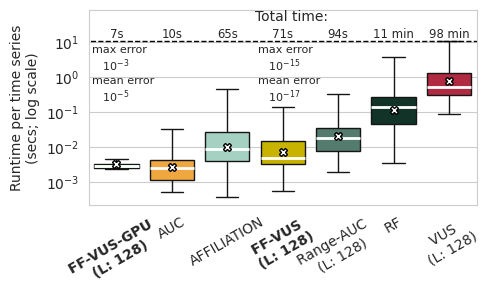

In [9]:
# What is the execution time difference
median_times = df.groupby('Metric')['Metric time'].mean()
order = median_times.sort_values().index.to_list()

fig = plt.figure(figsize=(5, 3.1))

medianprops = dict(linestyle='-', linewidth=2, color='white')
meanprops = dict(
    marker='X',
    markerfacecolor='white',
    markeredgecolor='black',
    markersize=6
)

axis = sns.boxplot(
    y='Metric time',
    x='Metric',
    hue='Metric',
    data=df,
    showfliers=False,
    log_scale=True,
    showmeans=True,
    meanprops=meanprops,
    medianprops=medianprops,
    palette=color_palette,
    order=order,
    saturation=1,
)
axis.set_ylabel('Runtime per time series\n(secs; log scale)')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=30)
axis.grid(visible=False, axis='x')
axis.hlines(y=10.5, xmin=-1, xmax=7, linestyle='--', lw=1, color='k')
axis.set_xlim(-0.5, 6.5)
axis.set_ylim(0, 80)
axis.text(2.5, 40, 'Total time:')

for i, metric in enumerate(order):
    if 'FF-' in metric:
        print(f'{metric} => max error: {dif_df[metric].max():.0e}, mean error: {dif_df[metric].mean():.0e}')
        axis.annotate(
            'max error\n   $10^{{-3}}$\nmean error\n   $10^{{-5}}$' if 'GPU' in metric else 'max error\n   $10^{{-15}}$\nmean error\n   $10^{{-17}}$',
            xy=(i, 10), 
            xytext=((i - .45, 0.2 + i*0)),
            fontsize=8
        )
    total = df.loc[df['Metric'] == metric, 'Metric time'].sum()
    if total > 100:
        label = f'{total/60:.0f} min'
    else:
        label = f'{total:.0f}s'
    axis.text(i, 25, label, ha='center', va='top', fontsize='small')
        

# Highlight the 2nd and 3rd xtick_label in bold
xticklabels = axis.get_xticklabels()
for idx in range(len(axis.get_xticklabels())):
    if 'FF-' in xticklabels[idx].get_text():
        xticklabels[idx].set_fontweight('bold')
    if '(L:' in xticklabels[idx].get_text(): 
        new_text = xticklabels[idx].get_text().replace('(', '\n(')
        xticklabels[idx].set_text(new_text)
axis.set_xticks(axis.get_xticks())
axis.set_xticklabels([label.get_text() for label in xticklabels])

# # Remove borders around the boxes but keep whiskers and caps
# for j, patch in enumerate(axis.patches):
#     facecolor = patch.get_facecolor()
#     if all([x == 1 for x in facecolor]):
#         patch.set_facecolor((1, 1, 1, 0.0))  # alpha = 0.0
#         patch.set_edgecolor((0, 0, 0, 1.0))  # fully opaque border
#         patch.set_linewidth(1.5)

#         axis.lines[j * 6 + 4].set_color('black')    # 6 lines per box and usually the median is the 4th
#         axis.lines[j * 6 + 4].set_linewidth(1.5)
#     else:
#         patch.set_edgecolor(facecolor)
#         patch.set_linewidth(0.5)

finalize_plot(save_fig_path, 'exec_time_comparison_tsb')

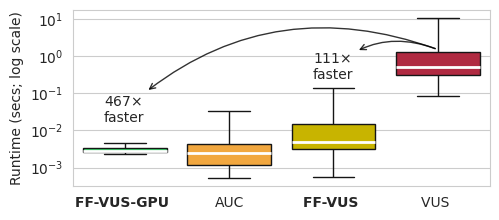

In [10]:
# What is the execution time difference
curr_df  = df[df['Metric'].isin(['AUC', 'FF-VUS-GPU (L: 128)', 'FF-VUS (L: 128)', 'VUS (L: 128)'])]
median_times = curr_df.groupby('Metric')['Metric time'].mean()
order = median_times.sort_values().index.to_list()

plt.figure(figsize=(5.1, 2.3))

axis = sns.boxplot(
    y='Metric time',
    x='Metric',
    hue='Metric',
    data=curr_df,
    showfliers=False,
    log_scale=True,
    showmeans=False,
    meanprops=meanprops,
    medianprops=medianprops,
    palette=color_palette,
    order=order,
    saturation=1,
)
axis.set_ylabel('Runtime (secs; log scale)')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=0)
axis.grid(visible=False, axis='x')

for i, metric in enumerate(order):
    if 'FF-' in metric:
        axis.annotate(
            f'{speed_up_dict[metric]:.0f}$\\times$\nfaster', 
            xy=(3, 1.5), 
            xytext=(i-0.2, 0.09 + i*0.6),
            arrowprops=dict(arrowstyle="<-", connectionstyle="arc3,rad=-.3", color='k', alpha=0.8),
            # ha='center',
            va='top'
        )

# Highlight the 2nd and 3rd xtick_label in bold
xticklabels = axis.get_xticklabels()
for idx in range(len(axis.get_xticklabels())):
    if 'FF-' in xticklabels[idx].get_text():
        xticklabels[idx].set_fontweight('bold')
    if '(L:' in xticklabels[idx].get_text(): 
        new_text = xticklabels[idx].get_text().replace('(L: 128)', '')
        xticklabels[idx].set_text(new_text)
axis.set_xticks(axis.get_xticks())
axis.set_xticklabels([label.get_text() for label in xticklabels])

finalize_plot(save_fig_path, 'exec_time_comparison_tsb_small')

### Error boxplot

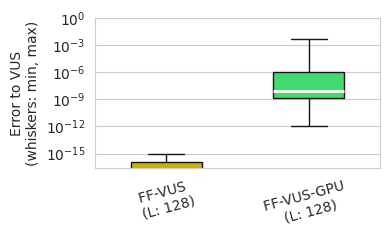

In [11]:
plt.figure(figsize=(4, 2.5))

axis = sns.boxplot(
    dif_df, 
    showfliers=False, 
    fill=True, 
    flierprops={"marker": "o"},
    medianprops=medianprops,
    width=.5, 
    palette=color_palette, 
    saturation=1,
    whis=[0, 100]
)
axis.set_ylabel('Error to VUS\n(whiskers: min, max)')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=15)
axis.grid(visible=False, axis='x')
axis.set_yscale('log')
axis.set_yticks([10**-x for x in range(0, 16)][::3])

# axis.annotate(f'Max error\n   9e-16', (0 - 0.2, 0.00005))
# axis.annotate(f'Max error\n   {dif_df['FF-VUS-GPU (L: 128)'].max():.3f}', (1 - 0.2, 0.00005))

# Highlight the 2nd and 3rd xtick_label in bold
xticklabels = axis.get_xticklabels()
for idx in range(len(axis.get_xticklabels())):
    if '(L:' in xticklabels[idx].get_text(): 
        new_text = xticklabels[idx].get_text().replace('(', '\n(')
        xticklabels[idx].set_text(new_text)
axis.set_xticks(axis.get_xticks())
axis.set_xticklabels([label.get_text() for label in xticklabels])

finalize_plot(save_fig_path, 'ffvus_error_analysis_tsb')

## Experiment 2: All metrics with default parameters on the synthetic datasets

In [37]:
curr_experiment_path = os.path.join(experiments_path, 'allmetrics_defparams_syn', 'results')
df = load_results(curr_experiment_path)    
df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 70/70 [00:00<00:00, 432.53it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Metric,Metric value,Metric time,Slope size,Step,Global mask,...,Anomaly coordinates time,Safe mask time,Thresholds time,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time
2596,syn_len_32768_n_10_avglen_10.npz,32768,10,10.0,Range-AUC (L: 128),0.227421,0.027629,128.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3173,syn_len_100000_n_10_avglen_500.npz,100000,10,500.5,RF,0.411592,0.489425,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1637,syn_len_100000_n_50_avglen_10.npz,100000,50,10.0,VUS (L: 128),0.936196,7.149265,128.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Time series characteristics runtime analysis

In [38]:
length_analysis_df = df[df['Length'] != 100_000]
n_anomalies_analysis_df = df[np.logical_and(df['Time series'].str.contains('len_100000_'), df['Time series'].str.contains('_avglen_10.npz'))]
avg_anomaly_length_analysis_df = df[df['Time series'].str.contains('len_100000_n_10_')]

avg_anomaly_length_analysis_df.loc[:, 'Anomalies average length'] = avg_anomaly_length_analysis_df.apply(lambda row: int(row['Time series'].split('_')[-1].replace('.npz', '')), axis=1)
n_anomalies_analysis_df.loc[:, 'Number of anomalies'] = n_anomalies_analysis_df.apply(lambda row: int(row['Time series'].split('_')[-3]), axis=1)

analysis_dfs = [
    length_analysis_df, 
    n_anomalies_analysis_df, 
    avg_anomaly_length_analysis_df
]
attributes = ["Length", "Number of anomalies", "Anomalies average length"]

/home/sylli/anaconda3/envs/ffvus/lib/python3.12/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)
/tmp/ipykernel_18869/693262018.py:2: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


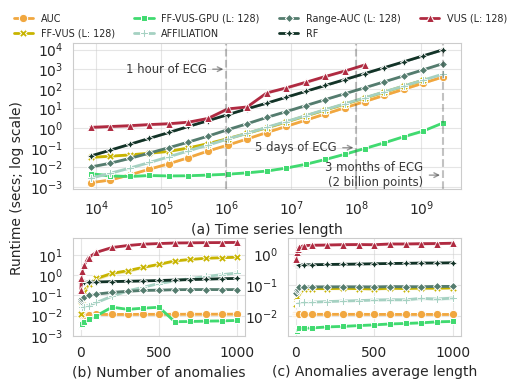

In [39]:
fig = plt.figure(figsize=(5, 3.8))
gs = GridSpec(2, 2, figure=fig, height_ratios=[3, 2], wspace=0.25, hspace=0.4)
attr_axis = {
    "Length": gs[0, :],
    "Number of anomalies": gs[1, 0],
    "Anomalies average length": gs[1, 1],
}
abc_numbered = {0: 'a', 1: 'b', 2: 'c'}

legend_axis = None
for i, attribute in enumerate(attributes):
    axis = fig.add_subplot(attr_axis[attribute])
    curr_df = analysis_dfs[i]

    sns.lineplot(
        x=attribute,
        y='Metric time',
        hue='Metric',
        data=curr_df,
        ax=axis,
        palette=color_palette,
        markers=True,
        style='Metric',
        dashes=False,
        linewidth=2,
        zorder=1,
        estimator=np.median
    )
    axis.set_yscale('log')
    axis.grid(axis='both', alpha=0.5)
    axis.set_xlabel(f"({abc_numbered[i]}) {attribute if attribute != 'Length' else "Time series length"}")
    axis.set_ylabel('')

    if attribute == "Length":
        axis.set_xscale('log', base=10)
    if i != 0:
        axis.get_legend().remove()
        if i == 1:
            axis.set_yticks([0.001, 0.01, 0.1, 1, 10])    
    else:
        legend_axis = axis

        axis.set_yticks([0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000])

        # 1 million points (~1 hour of ECG)
        x_val = 1e6
        y_val = 1000
        curr_color = "#383838"
        axis.annotate("1 hour of ECG",
                    xy=(x_val, y_val), xytext=(x_val / 2, y_val),
                    ha='right', va='center', fontsize='small', color=curr_color,
                    arrowprops=dict(arrowstyle="->", color=curr_color, alpha=0.5))
        axis.axvline(x=x_val, ymin=0, ymax=20000, color=curr_color, linestyle='--', alpha=0.3)

        # 100 million points (~5 days of ECG)
        x_val = 1e8
        y_val = 0.1
        axis.annotate("5 days of ECG",
                    xy=(x_val, y_val), xytext=(x_val / 2, y_val),
                    ha='right', va='center', fontsize='small', color=curr_color,
                    arrowprops=dict(arrowstyle="->", color=curr_color, alpha=0.5))
        axis.axvline(x=x_val, ymin=0, ymax=20000, color=curr_color, linestyle='--', alpha=0.3)

        # 1 billion points (~3 months of ECG)
        x_val = 2**31
        y_val = 0.004
        axis.annotate("3 months of ECG\n(2 billion points)",
                    xy=(x_val, y_val), xytext=(x_val / 2, y_val),
                    ha='right', va='center', fontsize='small', color=curr_color,
                    arrowprops=dict(arrowstyle="->", color=curr_color, alpha=0.5))
        axis.axvline(x=x_val, ymin=0, ymax=20000, color=curr_color, linestyle='--', alpha=0.3)

fig.text(
    0, 0.5,
    "Runtime (secs; log scale)",
    va='center',
    rotation='vertical',
)

if legend_axis:
    handles, labels = legend_axis.get_legend_handles_labels()
    legend_axis.get_legend().remove()
    fig.legend(
        handles,
        labels,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.98),
        ncol=4,#(len(labels)//2),
        # nrow=2,
        frameon=False,
        fontsize='x-small'
    )
finalize_plot(save_fig_path, 'exec_time_per_ts_char_syn')

### Computation step runtime analysis

In [40]:
rename_dict = {
    'Anomaly coordinates time': 'Anom.',
    'Safe mask time': 'Mask',
    'Thresholds time': 'Thresh.',
    'Score mask time': 'Scores',
    'Position time': 'Pos.',
    'Slopes time': 'Buffers',
    'Existence time': 'Existence',
    'Confusion matrix time': 'Conf. mat.',
    'Precision recall curve time': 'PR curve',
    'Integral time': 'Integral',
}
rename_dict = {k: f'({chr(i + 97)}) {v}' for i, (k, v) in enumerate(rename_dict.items())}

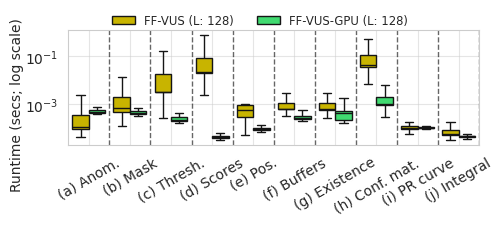

In [41]:
time_analysis_cols = [x for x in df.columns if 'time' in x and x != 'Metric time']
metrics = ['FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)']
curr_df = df[df['Metric'].isin(metrics)]

fig, axis = plt.subplots(1, 1, figsize=(5, 2.2))
for i, col in enumerate(time_analysis_cols):
    sns.boxplot(
        curr_df, 
        ax=axis, 
        x=i, 
        y=col, 
        log_scale=True, 
        legend=(i == 0), 
        hue='Metric',
        palette=color_palette, 
        showfliers=False,
        saturation=1
    )
    if i != 0:
        axis.set_xticks(np.arange(len(time_analysis_cols)), [rename_dict[x] for x in time_analysis_cols])
    else:
        axis.set_xticks(np.arange(len(time_analysis_cols)), [])

    axis.axvline(x=i+0.5, linestyle='--', color='k', lw=1, alpha=0.6)
axis.set_title('')
axis.set_ylabel('')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=30)
axis.grid(axis='both', alpha=0.5)
axis.legend()

fig.text(
    0, 0.57,
    "Runtime (secs; log scale)",
    va='center',
    rotation='vertical',
)

handles, labels = axis.get_legend_handles_labels()
axis.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.03),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'per_part_runtime_syn')

## Experiment 3: VUS / Buffer & Step comparison / TSB

### Buffer comparison

In [42]:
curr_experiment_path = os.path.join(experiments_path, 'vus_buffer_comparison_tsb', 'results')
df = load_results(curr_experiment_path)    
df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 30/30 [00:00<00:00, 78.20it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Step,Global mask,Slopes,Existence,Confusion matrix,...,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time,Metric,Metric value,Metric time
4343,OPPORTUNITY/S2-ADL3.test.csv@52.out,33983,2,456.5,32,1.0,True,precomputed,optimized,dynamic_plus,...,0.000339,0.000075,0.000052,0.000104,0.000333,0.000036,0.000028,FF-VUS (L: 128),0.110875,0.002184
7482,KDD21/127_UCR_Anomaly_GP711MarkerLFM5z1_5000_6...,11999,1,44.0,256,1.0,True,function,True,dynamic_plus,...,0.000032,0.000070,0.000190,0.000163,0.000550,0.000088,0.000035,FF-VUS-GPU (L: 128),0.762778,0.002717
22530,KDD21/033_UCR_Anomaly_DISTORTEDInternalBleedin...,7414,1,170.0,32,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VUS (L: 128),0.341641,0.063998


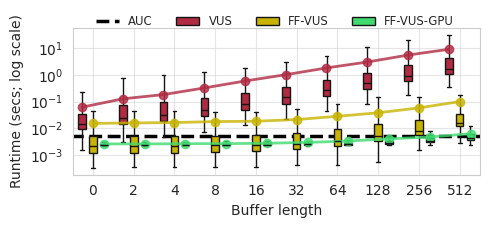

In [43]:
order = ['VUS (L: 128)', 'FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)']

fig, axis = plt.subplots(1, 1, figsize=(5, 2.2))

# First create the boxplot
axis.hlines(y=df_auc['Metric time'].mean(), xmin=-1, xmax=10, linestyle='--', lw=2.5, color='k', label='AUC')
sns.boxplot(
    ax=axis,
    y='Metric time', 
    x='Slope size', 
    hue='Metric', 
    data=df, 
    showfliers=False, 
    log_scale=True, 
    palette=color_palette, 
    saturation=1,
    gap=.3,
    hue_order=order
)


# Add lines connecting means for each metric
for i, metric in enumerate(order):
    means = df[df['Metric'] == metric].groupby('Slope size')['Metric time'].mean()
    axis.plot(np.arange(len(means)) + (i - 1) * 0.27, means, '-o', lw=2, label=f'{metric} mean', alpha=0.8, color=color_palette[metric])

plt.xlabel('Buffer length')
plt.ylabel('Runtime (secs; log scale)')
plt.grid(axis='both', alpha=0.5)
axis.set_xlim(-0.5, 9.5)

handles, labels = axis.get_legend_handles_labels()
labels = [label.replace(' (L: 128)', '').replace(' mean', '') for label in labels[:4]]
axis.get_legend().remove()
fig.legend(
    handles[:4],
    labels,
    loc='upper center',
    bbox_to_anchor=(0.56, 1.04),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'exec_time_buffer_comparison')

### Step comparison

In [44]:
curr_experiment_path = os.path.join(experiments_path, 'vus_step_comparison_tsb', 'results')
df_step = load_results(curr_experiment_path)    
df_step['Metric'] = df_step['Metric'].map(formal_names)
df_step.sample(3)

100%|██████████| 20/20 [00:00<00:00, 76.35it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Step,Global mask,Slopes,Existence,Confusion matrix,...,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time,Metric,Metric value,Metric time
37196,YAHOO/YahooA4Benchmark-TS18_data.out,1679,1,1.0,512,16,True,function,True,dynamic_plus,...,0.000033,0.000070,0.000194,0.000160,0.000293,0.000088,0.000035,FF-VUS-GPU (L: 128),0.771398,0.002352
24925,OPPORTUNITY/S3-ADL2.test.csv@53.out,27456,2,709.5,512,128,True,function,True,dynamic_plus,...,0.000033,0.000068,0.000190,0.000161,0.000269,0.000089,0.000035,FF-VUS-GPU (L: 128),0.197978,0.002397
18669,KDD21/015_UCR_Anomaly_DISTORTEDECG4_5000_16800...,199999,1,300.0,512,64,True,precomputed,optimized,dynamic_plus,...,0.001655,0.000109,0.000058,0.000099,0.000331,0.000040,0.000029,FF-VUS (L: 128),0.085705,0.008565


In [45]:
df_vus_512 = df[np.logical_and(df['Metric'] == 'VUS (L: 128)', df['Slope size'] == 512)]

In [46]:
df_vus_512_control = df_vus_512.set_index('Time series')['Metric value']

df_step['Error'] = df_step.apply(lambda row: row['Metric value'] - df_vus_512_control.loc[row['Time series']], axis=1)
df_step.sample(3)

,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Step,Global mask,Slopes,Existence,Confusion matrix,...,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time,Metric,Metric value,Metric time,Error
33574,SVDB/850.test.csv@2.out,230399,2,391.0,512,16,True,precomputed,optimized,dynamic_plus,...,0.000224,0.000207,0.000182,0.001086,0.000073,0.000045,FF-VUS (L: 128),0.030859,0.020956,-0.000105
35162,YAHOO/Yahoo_A2synthetic_80_data.out,1420,3,3.0,512,8,True,precomputed,optimized,dynamic_plus,...,0.000124,0.000378,0.000432,0.001231,0.000117,0.000053,FF-VUS (L: 128),0.298235,0.002665,0.001326
27341,SMD/machine-2-3.test.csv@2.out,23688,10,26.9,512,512,True,precomputed,optimized,dynamic_plus,...,0.000638,0.000114,0.000296,0.002130,0.000034,0.000024,FF-VUS (L: 128),0.174869,0.004400,-0.005136


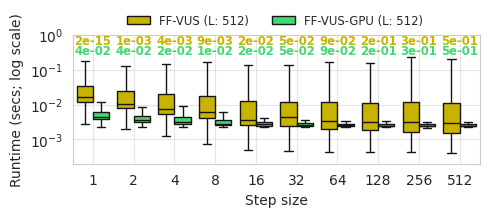

In [47]:
fig, axis = plt.subplots(1, 1, figsize=(5, 2.1))
# plt.hlines(df_vus_512['Metric time'].mean(), xmin=-1, xmax=512, lw=2.5, color=color_palette['VUS (L: 128)'], linestyle='--', label='VUS (L: 512)')
sns.boxplot(
    y='Metric time', 
    x='Step', 
    data=df_step, 
    showfliers=False, 
    log_scale=True,
    hue='Metric',
    palette=color_palette,
    saturation=1,
    ax=axis
)
axis.set_xlabel('Step size')
axis.set_ylabel('Runtime (secs; log scale)')
axis.tick_params(axis='x', labelrotation=0)
axis.grid(axis='both', alpha=0.5)
axis.set_ylim(0.0002, 1)

# annotate error info above each Step box
steps = sorted(df_step['Step'].dropna().unique())
for i, s in enumerate(steps):
    # errs = df_step.loc[df_step['Step'] == s][['Metric', 'Error']]
    # print(errs)
    
    for j, metric in enumerate(metrics[::-1]):
        axis.text(i, 
            .23 + j*0.2, 
            f'{df_step[np.logical_and(df_step['Metric'] == metric, df_step['Step'] == s)]['Error'].abs().max():.0e}', 
            ha='center', 
            va='bottom', 
            fontsize='small',
            color=color_palette[metric],
            weight='bold',
            # bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8)
        )

handles, labels = axis.get_legend_handles_labels()
labels = [label.replace(' (L: 128)', ' (L: 512)') for label in labels]
axis.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.56, 1.04),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'step_comparison')

/home/sylli/anaconda3/envs/ffvus/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


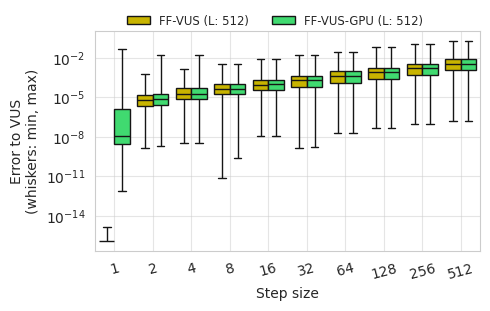

In [48]:
fig, axis = plt.subplots(1, 1, figsize=(5, 3))    
sns.boxplot(
    y='Error', 
    x='Step', 
    data=df_step, 
    showfliers=False, 
    log_scale=True,
    hue='Metric',
    palette=color_palette,
    saturation=1,
    ax=axis,
    whis=[0, 100]
)
axis.set_xlabel('Step size')
axis.set_ylabel('Error to VUS\n(whiskers: min, max)')
axis.tick_params(axis='x', labelrotation=15)
# axis.set_yticks([10**i for i in range(-3, 4)])
axis.grid(axis='both', alpha=0.5)

handles, labels = axis.get_legend_handles_labels()
labels = [label.replace(' (L: 128)', ' (L: 512)') for label in labels]
axis.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.56, 1.04),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'error_step_comparison')

### Step rank evaluation

In [57]:
from scipy.stats import spearmanr, kendalltau

curr_experiment_path = os.path.join(experiments_path, 'compare_rank', 'results')
df = load_results(curr_experiment_path)
df = df.drop('index', axis=1)
# df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 20/20 [00:00<00:00, 38.36it/s]


,Time series,Metric,Step,Detector,Score,Runtime
86665,OPPORTUNITY/S3-ADL4.test.csv@54.out,FF-VUS,128.0,OCSVM,0.077654,0.005124
337015,SMD/machine-2-3.test.csv@32.out,FF-VUS-GPU,32.0,LOF,0.322839,0.002852
131812,YAHOO/YahooA3Benchmark-TS91_data.out,FF-VUS,16.0,AE,0.702037,0.002610


In [58]:
total_runtimes = df[df['Step'] == 1].groupby('Metric')['Runtime'].sum()

for metric, secs in total_runtimes.items():
    hrs = int(secs // 3600)
    mins = int((secs % 3600) // 60)
    print(f"{metric}: {hrs}h {mins}m")

FF-VUS: 0h 38m
FF-VUS-GPU: 0h 2m
VUS: 61h 33m


In [59]:
vus_df = df[df['Metric'] == 'VUS']
common_ts = vus_df['Time series'].unique()
df = df[np.logical_and(df['Time series'].isin(common_ts), df['Metric'] != 'VUS')]
df

,Time series,Metric,Step,Detector,Score,Runtime
12768,Daphnet/S03R03E4.test.csv@3.out,FF-VUS,1.0,AE,0.051531,0.027121
12769,Daphnet/S03R03E4.test.csv@3.out,FF-VUS,2.0,AE,0.051552,0.033644
12770,Daphnet/S03R03E4.test.csv@3.out,FF-VUS,4.0,AE,0.051585,0.017613
12771,Daphnet/S03R03E4.test.csv@3.out,FF-VUS,8.0,AE,0.051647,0.069846
12772,Daphnet/S03R03E4.test.csv@3.out,FF-VUS,16.0,AE,0.051764,0.002049
...,...,...,...,...,...,...
473635,KDD21/190_UCR_Anomaly_resperation4_70000_12843...,FF-VUS-GPU,32.0,POLY,0.000642,0.002815
473636,KDD21/190_UCR_Anomaly_resperation4_70000_12843...,FF-VUS-GPU,64.0,POLY,0.000748,0.002815
473637,KDD21/190_UCR_Anomaly_resperation4_70000_12843...,FF-VUS-GPU,128.0,POLY,0.000991,0.002829
473638,KDD21/190_UCR_Anomaly_resperation4_70000_12843...,FF-VUS-GPU,256.0,POLY,0.001384,0.002805


In [62]:
step_rank_results = []
vus_ts_unique = vus_df['Time series'].unique()
metrics_unique = df['Metric'].unique()
steps_unique = df['Step'].unique()

# Pre-index dataframes for faster lookup
vus_grouped = vus_df.set_index(['Time series', 'Detector'])['Score']
df_grouped = df.set_index(['Time series', 'Metric', 'Step', 'Detector'])['Score']

for ts in tqdm(vus_ts_unique):
    curr_vus = vus_grouped.loc[ts].sort_index()
    curr_vus_rank = curr_vus.rank(method='average')
    curr_vus_rank_values = curr_vus_rank.values

    for metric in metrics_unique:
        for step in steps_unique:
            try:
                curr_ff_step = df_grouped.loc[(ts, metric, step)].sort_index()
            except KeyError:
                continue
            curr_ff_rank = curr_ff_step.rank(method='average')
            curr_ff_rank_values = curr_ff_rank.values

            spear = spearmanr(curr_vus_rank_values, curr_ff_rank_values).correlation
            kend = kendalltau(curr_vus_rank_values, curr_ff_rank_values).correlation
            mean_diff = np.mean(np.abs(curr_vus_rank_values - curr_ff_rank_values))
            flips = np.mean(np.sign(curr_vus_rank_values[:, None] - curr_vus_rank_values[None, :]) !=
                    np.sign(curr_ff_rank_values[:, None] - curr_ff_rank_values[None, :]))

            step_rank_results.append({
                'Time series': ts,
                'Metric': metric,
                'Step': step,
                'Spearman': spear,
                'Kendall': kend,
                'Mean rank diff.': mean_diff,
                'Order flips': flips
            })
df_rank_results = pd.DataFrame(step_rank_results)
df_rank_results

  0%|          | 0/1884 [00:00<?, ?it/s]/tmp/ipykernel_18869/2449298812.py:18: PerformanceWarning: indexing past lexsort depth may impact performance.
  curr_ff_step = df_grouped.loc[(ts, metric, step)].sort_index()
100%|██████████| 1884/1884 [01:13<00:00, 25.69it/s]


,Time series,Metric,Step,Spearman,Kendall,Mean rank diff.,Order flips
0,Occupancy/room-occupancy-0.test.csv@1.out,FF-VUS,1.0,1.0,1.0,0.0,0.0
1,Occupancy/room-occupancy-0.test.csv@1.out,FF-VUS,2.0,1.0,1.0,0.0,0.0
2,Occupancy/room-occupancy-0.test.csv@1.out,FF-VUS,4.0,1.0,1.0,0.0,0.0
3,Occupancy/room-occupancy-0.test.csv@1.out,FF-VUS,8.0,1.0,1.0,0.0,0.0
4,Occupancy/room-occupancy-0.test.csv@1.out,FF-VUS,16.0,1.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...
37675,MITDB/117.test.csv@2.out,FF-VUS-GPU,32.0,1.0,1.0,0.0,0.0
37676,MITDB/117.test.csv@2.out,FF-VUS-GPU,64.0,1.0,1.0,0.0,0.0
37677,MITDB/117.test.csv@2.out,FF-VUS-GPU,128.0,1.0,1.0,0.0,0.0
37678,MITDB/117.test.csv@2.out,FF-VUS-GPU,256.0,1.0,1.0,0.0,0.0


In [63]:
df_rank_results.groupby(['Metric', 'Step'])[['Spearman', 'Kendall', 'Mean rank diff.', 'Order flips']].mean()

Spearman   Kendall  Mean rank diff.  Order flips
Metric     Step                                                   
FF-VUS     1.0    1.000000  1.000000         0.000000     0.000000
           2.0    0.999918  0.999643         0.001946     0.000162
           4.0    0.999833  0.999276         0.003981     0.000332
           8.0    0.999457  0.997820         0.011943     0.000995
           16.0   0.998563  0.995084         0.026539     0.002248
           32.0   0.996625  0.989386         0.056352     0.004858
           64.0   0.992245  0.978672         0.111200     0.009753
           128.0  0.983502  0.959482         0.204264     0.018526
           256.0  0.970727  0.931570         0.339968     0.031287
           512.0  0.946804  0.887652         0.546576     0.051383
FF-VUS-GPU 1.0    0.997317  0.992363         0.039544     0.003553
           2.0    0.998907  0.996104         0.021364     0.001887
           4.0    0.999178  0.996915         0.016720     0.001445
           8.0    0.999072  0.996472         0.019285     0.001666
           16.0   0.998469  0.994793         0.028397     0.002462
           32.0   0.996541  0.989212         0.057590     0.005020
           64.0   0.992196  0.978586         0.111952     0.009871
           128.0  0.983427  0.959357         0.205547     0.018754
           256.0  0.970663  0.931463         0.340941     0.031479
           512.0  0.946736  0.887528         0.547726     0.051589

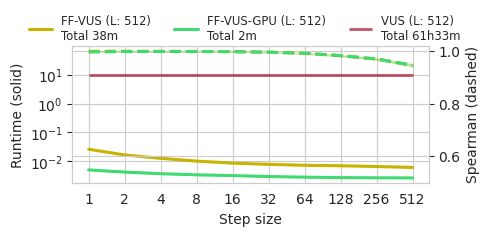

In [82]:
fig, ax1 = plt.subplots(figsize=(5, 2.1))

steps = [2**i for i in range(10)]
ax1.set_xscale('log', base=2)
ax1.set_xticks(steps)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

ax1.set_yscale('log')
runtime_lines = sns.lineplot(
    data=df,
    x='Step', y='Runtime', hue='Metric',
    palette=color_palette, ax=ax1, lw=2.2
)
ax1.set_ylabel("Runtime (solid)")
ax1.set_xlabel("Step size")

vus_mean = vus_df['Runtime'].mean()
ax1.hlines(y=vus_mean, xmin=1, xmax=512, lw=2, ls='solid', color=color_palette['VUS (L: 128)'], label='VUS', alpha=0.8)

ax1.set_yticks([10**(x) for x in [-3, -2, -1, 0, 1]])
handles1, labels1 = ax1.get_legend_handles_labels()
ax1.legend().remove()
ax1.set_ylim(0.001, 50)

ax2 = ax1.twinx()
spearman_lines = sns.lineplot(
    data=df_rank_results,
    x='Step', y='Spearman', hue='Metric',
    palette=color_palette, ax=ax2,
    linestyle='--', lw=2.2
)
ax2.set_ylabel("Spearman (dashed)")
ax2.legend().remove()

# Adjust y-axis limits to better show the differences
ax1.set_ylim(0.0018, 100)
ax2.set_ylim(0.5, 1.02)

fig.legend(
    handles1,
    [x + ' (L: 512)\nTotal' + (f' {int(secs // 3600)}h' if int(secs // 3600) > 0 else ' ') + f'{int((secs % 3600) // 60)}m' for x, (metric, secs) in zip(labels1, total_runtimes.items())],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.13),
    ncol=3,
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'step_rank_comparison')

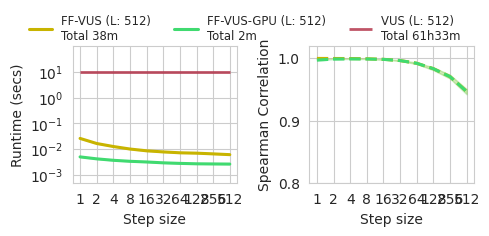

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(5, 2.1))

steps = [2**i for i in range(10)]

# === LEFT SUBPLOT: Runtime ===
ax1.set_xscale('log', base=2)
ax1.set_xticks(steps)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax1.set_yscale('log')

runtime_lines = sns.lineplot(
    data=df,
    x='Step', y='Runtime', hue='Metric',
    palette=color_palette, ax=ax1, lw=2.2
)

ax1.set_ylabel("Runtime (secs)")
ax1.set_xlabel("Step size")

vus_mean = vus_df['Runtime'].mean()
ax1.hlines(
    y=vus_mean, xmin=1, xmax=512, 
    lw=2, ls='solid', 
    color=color_palette['VUS (L: 128)'], 
    label='VUS', alpha=0.8
)

ax1.set_yticks([10**(x) for x in [-3, -2, -1, 0, 1]])
ax1.set_ylim(0.0005, 100)

handles1, labels1 = ax1.get_legend_handles_labels()
ax1.legend().remove()

# === RIGHT SUBPLOT: Spearman Correlation ===
ax2.set_xscale('log', base=2)
ax2.set_xticks(steps[::2])
ax2.get_xaxis().set_major_formatter(plt.ScalarFormatter())

spearman_lines = sns.lineplot(
    data=df_rank_results,
    x='Step', y='Spearman', hue='Metric',
    palette=color_palette, ax=ax2,
    linestyle='--', lw=2.2
)

ax2.set_ylabel("Spearman Correlation")
ax2.set_xlabel("Step size")
ax2.set_ylim(0.8, 1.02)
ax2.legend().remove()

# === SHARED LEGEND ===
fig.legend(
    handles1,
    [x + ' (L: 512)\nTotal' + (f' {int(secs // 3600)}h' if int(secs // 3600) > 0 else ' ') + f'{int((secs % 3600) // 60)}m' 
     for x, (metric, secs) in zip(labels1, total_runtimes.items())],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.13),
    ncol=3,
    frameon=False,
    fontsize='small'
)

plt.tight_layout()
finalize_plot(save_fig_path, 'step_rank_comparison')

## Experiment 4: Equivalence to AUC

In [27]:
curr_experiment_path = os.path.join(experiments_path, 'vus_ffvus_auc_0_tsb', 'results')
df = load_results(curr_experiment_path)    
df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 4/4 [00:00<00:00, 80.10it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Step,Global mask,Slopes,Existence,Confusion matrix,...,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time,Metric,Metric value,Metric time
450,OPPORTUNITY/S1-ADL5.test.csv@71.out,30047,2,609.0,0.0,1.0,True,function,0.0,dynamic_plus,...,0.000033,0.000068,0.000175,0.000001,0.000221,0.000084,0.000034,FF-VUS-GPU (L: 128),0.177368,0.002248
6853,YAHOO/YahooA3Benchmark-TS63_data.out,1679,10,1.0,0.0,NaN,NaN,NaN,False,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VUS (L: 128),0.122567,0.007506
4023,OPPORTUNITY/S1-ADL5.test.csv@114.out,30126,2,609.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AUC,0.099563,0.002555


In [28]:
values_df = df[['Time series', 'Metric', 'Metric value']]
values_df = values_df.pivot(columns='Metric', index='Time series', values='Metric value')
dif_df = values_df.copy()
for metric in metrics: 
    dif_df[metric] = values_df[metric] - values_df['AUC']

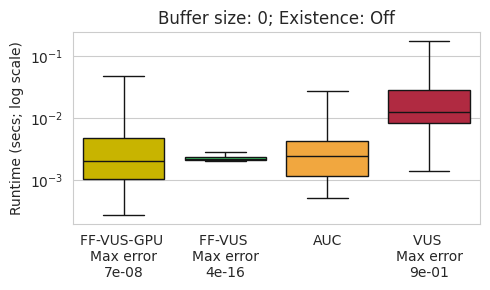

In [29]:
metrics = df['Metric'].unique()
median_times = df.groupby('Metric')['Metric time'].median()
order = median_times.sort_values().index.to_list()

fig, axis = plt.subplots(1, 1, figsize=(5, 3))
sns.boxplot(
    y='Metric time', 
    x='Metric', 
    hue='Metric', 
    data=df, 
    showfliers=False, 
    log_scale=True, 
    palette=color_palette, 
    order=order, 
    ax=axis,
    saturation=1
)
axis.set_xlabel('')
axis.set_ylabel('Runtime (secs; log scale)')
axis.set_title('Buffer size: 0; Existence: Off')
axis.set_xticks(np.arange(len(metrics)), [x.replace('(L: 128)', f'\nMax error\n{dif_df.max()[x]:.0e}') for x in metrics])

finalize_plot(save_fig_path, 'exec_time_auc_equivalence')

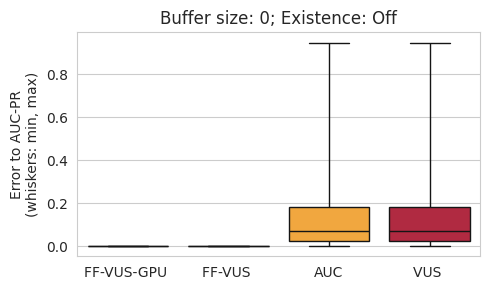

In [30]:
fig, axis = plt.subplots(1, 1, figsize=(5, 3))

sns.boxplot(
    dif_df.abs(), 
    showfliers=True, 
    palette=color_palette, 
    order=order, 
    log_scale=False, 
    ax=axis,
    saturation=1,
    whis=[0, 100]
)
axis.set_xlabel('')
axis.set_ylabel('Error to AUC-PR\n(whiskers: min, max)')
axis.set_title('Buffer size: 0; Existence: Off')
axis.set_xticks(np.arange(len(metrics)), [x.replace('(L: 128)', '(L: 0, E: Off)') for x in metrics])
axis.set_xticks(np.arange(len(metrics)), [x.replace('(L: 128)', '') for x in metrics])

finalize_plot(save_fig_path, 'error_auc_equivalence')

## Experiment 5: MSAD pipeline with VUS for evaluation 

In [22]:
curr_experiment_path = os.path.join(experiments_path, 'compare_train_metrics', 'sylli_logs_29012026')

result_files = [file for file in os.listdir(curr_experiment_path) if file.endswith('.csv')]

df = pd.DataFrame()
for file in tqdm(result_files):
    file_path = os.path.join(curr_experiment_path, file)
    curr_df = pd.read_csv(file_path, index_col=0).reset_index()
    curr_df = curr_df.rename(columns={
        'epoch': 'Epoch',
        'train_time': 'Train time',
        'val_time': 'Val time',
        'total_time': 'Total time',
        'train_pct': 'Train %',
        'val_pct': 'Val %'
    })
    curr_df['Metric'] = file.split('_')[3]
    df = pd.concat([df, curr_df], ignore_index=True)

df
df['Metric'] = df['Metric'].map(formal_names)
df.sample(10)

100%|██████████| 4/4 [00:00<00:00, 443.87it/s]


,Epoch,Train time,Val time,Total time,Train %,Val %,Metric
40,40,45.538743,134.286443,179.825185,25.323896,74.676104,VUS (L: 128)
23,23,44.927398,132.555862,177.483260,25.313597,74.686403,VUS (L: 128)
333,30,49.095515,0.972004,50.067519,98.058614,1.941386,AUC
230,28,45.496431,0.926822,46.423253,98.003540,1.996460,FF-VUS-GPU (L: 128)
362,59,45.800756,0.868434,46.669189,98.139171,1.860829,AUC
387,84,46.987569,0.871333,47.858902,98.179370,1.820630,AUC
295,93,46.304079,0.928863,47.232942,98.033442,1.966558,FF-VUS-GPU (L: 128)
78,78,45.177963,137.342695,182.520657,24.752246,75.247754,VUS (L: 128)
127,26,44.916208,2.591601,47.507808,94.544895,5.455105,FF-VUS (L: 128)
238,36,45.621155,0.929121,46.550276,98.004048,1.995952,FF-VUS-GPU (L: 128)


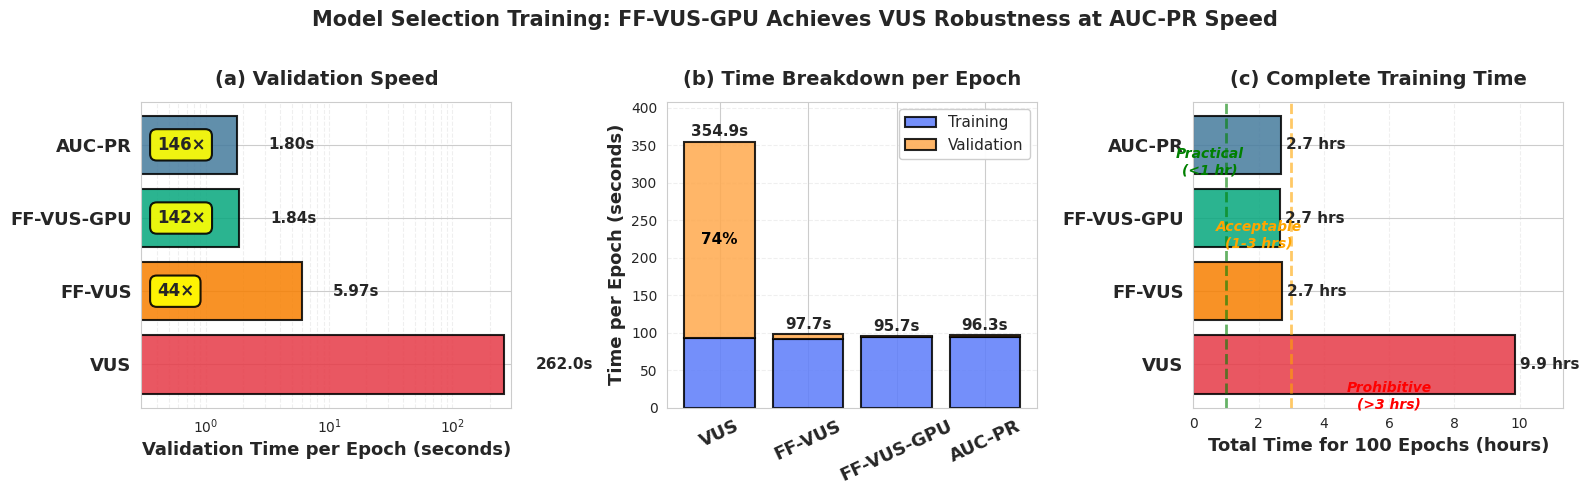

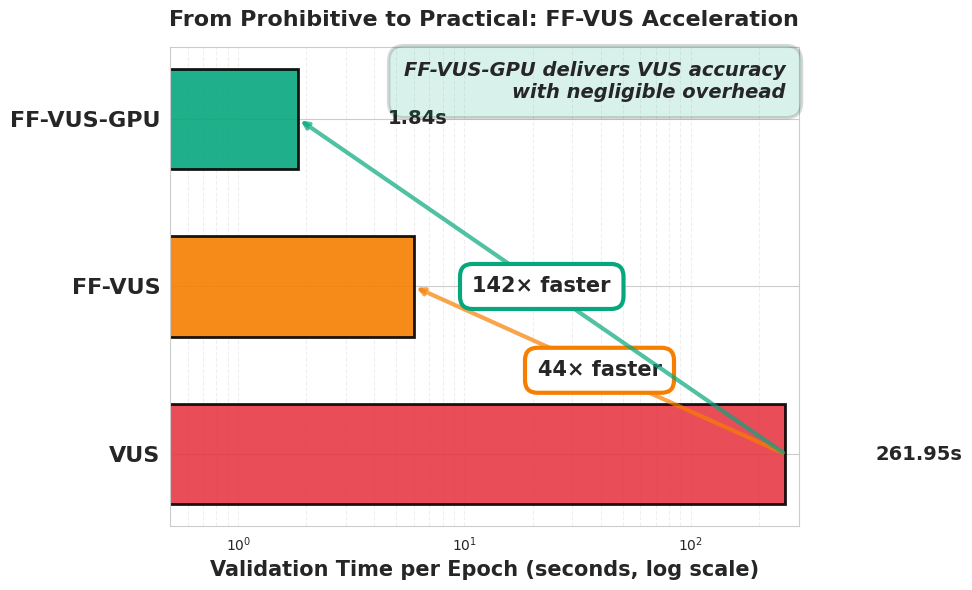


MANUSCRIPT-READY STATISTICS:

Validation time per epoch:
  VUS            : 261.95s  ( 73.8% overhead)
  FF-VUS         :   5.97s  (  6.1% overhead)
  FF-VUS-GPU     :   1.84s  (  2.0% overhead)
  AUC-PR         :   1.80s  (  1.9% overhead)

Speedup factors relative to VUS:
  FF-VUS         :  43.9×
  FF-VUS-GPU     : 142.3×
  AUC-PR         : 145.7×

Time for 100 epochs:
  VUS            : 9.9 hours
  FF-VUS         : 2.7 hours
  FF-VUS-GPU     : 2.7 hours
  AUC-PR         : 2.7 hours



In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

grouped = df.groupby('Metric').agg({
    'Train time': 'mean',
    'Val time': 'mean',
    'Total time': 'mean',
    'Train %': 'mean',
    'Val %': 'mean'
}).reset_index()

# Create the main figure - single row, three panels
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Define colors - make them distinct and professional
colors = {
    'VUS (L: 128)': '#E63946',      # Red - problematic
    'FF-VUS (L: 128)': '#F77F00',   # Orange - better
    'FF-VUS-GPU (L: 128)': '#06A77D', # Green - best
    'AUC': '#457B9D'                # Blue - baseline
}

metric_order = ['VUS (L: 128)', 'FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)', 'AUC']
grouped_sorted = grouped.set_index('Metric').loc[metric_order].reset_index()

# Nice readable metric labels
metric_labels = {
    'VUS (L: 128)': 'VUS',
    'FF-VUS (L: 128)': 'FF-VUS',
    'FF-VUS-GPU (L: 128)': 'FF-VUS-GPU',
    'AUC': 'AUC-PR'
}

# ============= Panel A: Validation Time (Log Scale) =============
ax = axes[0]
val_times = grouped_sorted['Val time'].values
y_pos = np.arange(len(grouped_sorted))

bars = ax.barh(y_pos, val_times, 
               color=[colors[m] for m in grouped_sorted['Metric']],
               edgecolor='black', linewidth=1.5, alpha=0.85)

ax.set_yticks(y_pos)
ax.set_yticklabels([metric_labels[m] for m in grouped_sorted['Metric']], 
                    fontsize=13, fontweight='bold')
ax.set_xlabel('Validation Time per Epoch (seconds)', fontsize=13, fontweight='bold')
ax.set_xscale('log')
ax.set_xlim(0.3, 300)
ax.grid(axis='x', alpha=0.3, linestyle='--', which='both')

# Add value labels
for i, (val, metric) in enumerate(zip(val_times, grouped_sorted['Metric'])):
    label = f'{val:.2f}s' if val < 10 else f'{val:.1f}s'
    x_pos_label = val * 1.8 if val > 1 else val * 3
    ax.text(x_pos_label, i, label, va='center', fontsize=11, fontweight='bold')

# Add speedup annotations relative to VUS
vus_time = grouped_sorted[grouped_sorted['Metric'] == 'VUS (L: 128)']['Val time'].values[0]
for i, (val, metric) in enumerate(zip(val_times, grouped_sorted['Metric'])):
    if metric != 'VUS (L: 128)':
        speedup = vus_time / val
        x_pos_speedup = 0.4
        ax.text(x_pos_speedup, i, f'{speedup:.0f}×', va='center', ha='left',
               fontsize=12, fontweight='bold', 
               bbox=dict(boxstyle='round,pad=0.4', facecolor='yellow', 
                        edgecolor='black', linewidth=1.5, alpha=0.9))

ax.set_title('(a) Validation Speed', fontsize=14, fontweight='bold', pad=12)

# ============= Panel B: Time Breakdown (Stacked) =============
ax = axes[1]
train_times = grouped_sorted['Train time'].values
val_times = grouped_sorted['Val time'].values
x_pos = np.arange(len(grouped_sorted))

# Create stacked bars
bars1 = ax.bar(x_pos, train_times, 
               color='#5C7CFA', edgecolor='black', linewidth=1.5, 
               label='Training', alpha=0.85)
bars2 = ax.bar(x_pos, val_times, bottom=train_times, 
               color='#FFA94D', edgecolor='black', linewidth=1.5,
               label='Validation', alpha=0.85)

ax.set_xticks(x_pos)
ax.set_xticklabels([metric_labels[m] for m in grouped_sorted['Metric']], 
                    fontsize=13, fontweight='bold', rotation=25)
ax.set_ylabel('Time per Epoch (seconds)', fontsize=13, fontweight='bold')
ax.set_ylim(0, max(grouped_sorted['Total time']) * 1.15)
ax.legend(loc='upper right', fontsize=11, framealpha=0.95)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add total time labels on top
for i, total in enumerate(grouped_sorted['Total time']):
    ax.text(i, total + 3, f'{total:.1f}s', ha='center', va='bottom',
           fontsize=11, fontweight='bold')

# Add validation overhead percentage labels on the orange section
for i, (train, val, total) in enumerate(zip(train_times, val_times, grouped_sorted['Total time'])):
    val_pct = (val/total) * 100
    if val_pct > 8:  # Only label if significant enough
        ax.text(i, train + val/2, f'{val_pct:.0f}%', ha='center', va='center',
               fontsize=11, fontweight='bold', color='black')

ax.set_title('(b) Time Breakdown per Epoch', fontsize=14, fontweight='bold', pad=12)

# ============= Panel C: Projected Training Time for 100 Epochs =============
ax = axes[2]
n_epochs = 100
total_times_100 = grouped_sorted['Total time'].values * n_epochs / 3600  # Convert to hours

bars = ax.barh(y_pos, total_times_100,
               color=[colors[m] for m in grouped_sorted['Metric']],
               edgecolor='black', linewidth=1.5, alpha=0.85)

ax.set_yticks(y_pos)
ax.set_yticklabels([metric_labels[m] for m in grouped_sorted['Metric']], 
                    fontsize=13, fontweight='bold')
ax.set_xlabel('Total Time for 100 Epochs (hours)', fontsize=13, fontweight='bold')
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, max(total_times_100) * 1.15)

# Add time labels
for i, (val, metric) in enumerate(zip(total_times_100, grouped_sorted['Metric'])):
    if val < 1.5:
        label = f'{val*60:.0f} min'
    else:
        label = f'{val:.1f} hrs'
    ax.text(val + 0.15, i, label, va='center', fontsize=11, fontweight='bold')

# Add reference lines for time zones
ax.axvline(1, color='green', linestyle='--', linewidth=2, alpha=0.6)
ax.axvline(3, color='orange', linestyle='--', linewidth=2, alpha=0.6)

# Zone annotations at the bottom
ax.text(0.5, 2.6, 'Practical\n(<1 hr)', ha='center', fontsize=10, 
       style='italic', color='green', fontweight='bold')
ax.text(2, 1.6, 'Acceptable\n(1-3 hrs)', ha='center', fontsize=10, 
       style='italic', color='orange', fontweight='bold')
ax.text(6, -0.6, 'Prohibitive\n(>3 hrs)', ha='center', fontsize=10, 
       style='italic', color='red', fontweight='bold')

ax.set_title('(c) Complete Training Time', fontsize=14, fontweight='bold', pad=12)

# Main title
fig.suptitle('Model Selection Training: FF-VUS-GPU Achieves VUS Robustness at AUC-PR Speed',
             fontsize=15, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.96])
# plt.savefig('/mnt/user-data/outputs/training_comparison_paper.png', dpi=300, bbox_inches='tight')
# print("\nMain paper figure saved!")
plt.show()

# ============= Create an additional "key message" figure =============
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# Focus on the three VUS variants
vus_metrics = ['VUS (L: 128)', 'FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)']
vus_data = grouped[grouped['Metric'].isin(vus_metrics)].copy()
vus_data['Metric_label'] = vus_data['Metric'].map(metric_labels)

# Sort by validation time
vus_data = vus_data.sort_values('Val time', ascending=False)

y_pos = np.arange(len(vus_data))
val_times = vus_data['Val time'].values

bars = ax.barh(y_pos, val_times,
               color=[colors[m] for m in vus_data['Metric']],
               edgecolor='black', linewidth=2, alpha=0.9, height=0.6)

ax.set_yticks(y_pos)
ax.set_yticklabels(vus_data['Metric_label'], fontsize=16, fontweight='bold')
ax.set_xlabel('Validation Time per Epoch (seconds, log scale)', fontsize=15, fontweight='bold')
ax.set_xscale('log')
ax.set_xlim(0.5, 300)
ax.grid(axis='x', alpha=0.3, linestyle='--', which='both')

# Add value labels
for i, (val, metric) in enumerate(zip(val_times, vus_data['Metric'])):
    x_pos_label = val * 2.5
    ax.text(x_pos_label, i, f'{val:.2f}s', va='center', fontsize=14, fontweight='bold')

# Add dramatic speedup arrows and boxes
vus_val = vus_data[vus_data['Metric'] == 'VUS (L: 128)']['Val time'].values[0]
vus_pos = list(vus_data['Metric']).index('VUS (L: 128)')

for i, (val, metric) in enumerate(zip(val_times, vus_data['Metric'])):
    if metric != 'VUS (L: 128)':
        speedup = vus_val / val
        
        # Draw arrow
        arrow_color = colors[metric]
        ax.annotate('', xy=(val, i), xytext=(vus_val, vus_pos),
                   arrowprops=dict(arrowstyle='->', lw=3, color=arrow_color, alpha=0.7))
        
        # Speedup label in the middle
        mid_x = np.sqrt(val * vus_val)  # Geometric mean for log scale
        mid_y = (i + vus_pos) / 2
        
        speedup_text = f'{speedup:.0f}× faster'
        ax.text(mid_x, mid_y, speedup_text, fontsize=15, fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.6', facecolor='white', 
                        edgecolor=arrow_color, linewidth=3),
               ha='center', va='center')

# Add a text box with the key message
textstr = 'FF-VUS-GPU delivers VUS accuracy\nwith negligible overhead'
props = dict(boxstyle='round,pad=0.8', facecolor='#06A77D', 
            edgecolor='black', linewidth=2.5, alpha=0.15)
ax.text(0.98, 0.97, textstr, transform=ax.transAxes, fontsize=14,
       verticalalignment='top', horizontalalignment='right',
       bbox=props, fontweight='bold', style='italic')

ax.set_title('From Prohibitive to Practical: FF-VUS Acceleration', 
            fontsize=16, fontweight='bold', pad=15)

plt.tight_layout()
# plt.savefig('/mnt/user-data/outputs/training_key_message.png', dpi=300, bbox_inches='tight')
# print("Key message figure saved!")
plt.show()

print("\n" + "="*70)
print("MANUSCRIPT-READY STATISTICS:")
print("="*70)
print("\nValidation time per epoch:")
for metric in ['VUS (L: 128)', 'FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)', 'AUC']:
    data = grouped[grouped['Metric'] == metric].iloc[0]
    print(f"  {metric_labels[metric]:15s}: {data['Val time']:6.2f}s  ({data['Val %']:5.1f}% overhead)")

print("\nSpeedup factors relative to VUS:")
vus_val = grouped[grouped['Metric'] == 'VUS (L: 128)']['Val time'].values[0]
for metric in ['FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)', 'AUC']:
    val = grouped[grouped['Metric'] == metric]['Val time'].values[0]
    print(f"  {metric_labels[metric]:15s}: {vus_val/val:5.1f}×")

print("\nTime for 100 epochs:")
for metric in ['VUS (L: 128)', 'FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)', 'AUC']:
    data = grouped[grouped['Metric'] == metric].iloc[0]
    hours = data['Total time'] * 100 / 3600
    if hours < 1.5:
        time_str = f"{hours*60:.0f} minutes"
    else:
        time_str = f"{hours:.1f} hours"
    print(f"  {metric_labels[metric]:15s}: {time_str}")

print("\n" + "="*70)

In [78]:
grouped = df.groupby('Metric')[['Train time', 'Val time', 'Total time']].sum().reset_index()
metric_order = ['VUS (L: 128)', 'FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)', 'AUC']
# metric_order = ['FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)', 'AUC']
grouped_sorted = grouped.set_index('Metric').loc[metric_order].reset_index()
grouped_sorted

,Metric,Train time,Val time,Total time
0,VUS (L: 128),9384.571102,26456.994730,35841.565831
1,FF-VUS (L: 128),9260.954428,602.814013,9863.768441
2,FF-VUS-GPU (L: 128),9475.828166,185.983542,9661.811708
3,AUC,9548.841936,181.566302,9730.408238


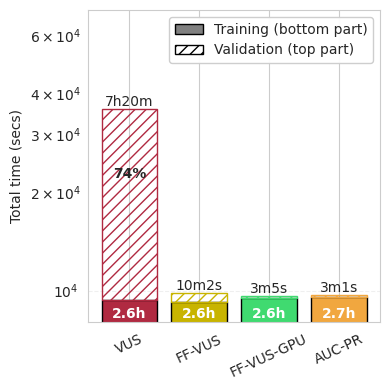

In [186]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(1, 1, figsize=(4, 4))

train_times = grouped_sorted['Train time'].values
val_times = grouped_sorted['Val time'].values
x_pos = np.arange(len(grouped_sorted))

# Create stacked bars
bars1 = ax.bar(x_pos, train_times, color=[color_palette[m] for m in grouped_sorted['Metric']], edgecolor='black', label='Training (bottom part)')
bars2 = ax.bar(x_pos, val_times, bottom=train_times, color='none', edgecolor=[color_palette[m] for m in grouped_sorted['Metric']], hatch='///', linewidth=1, label='Validation (top part)')

ax.set_xticks(x_pos)
ax.set_xticklabels([metric_labels[m] for m in grouped_sorted['Metric']], rotation=25)
ax.set_yticks([0, 3600, 7200, 10800, 14400, 18000, 21600, 25200, 28800, 32400, 36000][::2])
ax.set_yticklabels(['0', '1h', '2h', '3h', '4h', '5h', '6h', '7h', '8h', '9h', '10h'][::2])
ax.set_ylabel('Total time (secs)')
ax.set_ylim(8000, max(grouped_sorted['Total time']) * 2)
legend_handles = [
    Patch(facecolor='gray', edgecolor='black', label='Training (bottom part)'),
    Patch(facecolor='none', edgecolor='black', hatch='///', linewidth=1, label='Validation (top part)')
]
ax.legend(handles=legend_handles, loc='upper right', framealpha=0.95)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_yscale('log')

# Add total time labels on top
for i, (val, total) in enumerate(zip(val_times, grouped_sorted['Total time'])):
    if val >= 3600:
        hrs = int(val // 3600)
        mins = int((val % 3600) // 60)
        ax.text(i, total + 3, f'{hrs}h{mins}m', ha='center', va='bottom')
    elif val >= 60:
        ax.text(i, total + 3, f'{int(val // 60)}m{int(val % 60)}s', ha='center', va='bottom')
    else:
        ax.text(i, total + 3, f'{val:.1f}s', ha='center', va='bottom')

# Add validation overhead percentage labels on the orange section
for i, (train, val, total) in enumerate(zip(train_times, val_times, grouped_sorted['Total time'])):
    val_pct = (val/total) * 100
    ax.text(i, 8500, f'{train/3600:.1f}h', ha='center', va='center', weight='bold', color='white')
    if val_pct > 8:  # Only label if significant enough
        ax.text(i, train + val/2, f'{val_pct:.0f}%', ha='center', va='center', weight='bold')

# ax.set_title('Total time breakdown')
finalize_plot(save_fig_path, 'toy_example_time_breakdown')

In [83]:
grouped_mean = df.groupby('Metric')[['Train time', 'Val time', 'Total time']].mean()
grouped_mean

,Train time,Val time,Total time
Metric,,,
AUC,94.542989,1.797686,96.340676
FF-VUS (L: 128),91.692618,5.968456,97.661074
FF-VUS-GPU (L: 128),93.820081,1.841421,95.661502
VUS (L: 128),92.916546,261.950443,354.866988


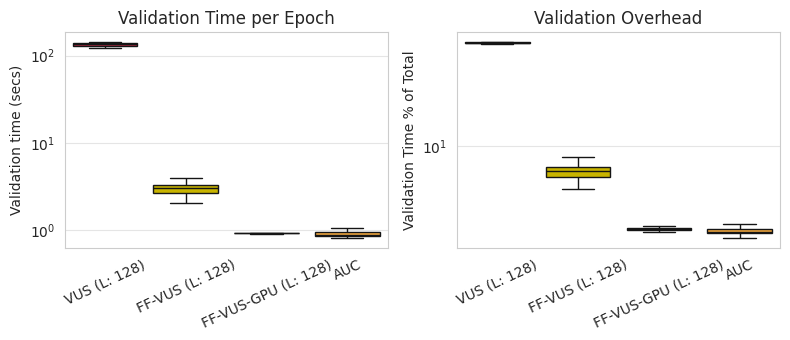

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

# Left plot: Validation time comparison
ax1 = axes[0]
df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Val time'] = df_plot['Val time'].astype(float)

sns.boxplot(
    data=df_plot,
    x='Metric',
    y='Val time',
    hue='Metric',
    palette=color_palette,
    ax=ax1,
    saturation=1,
    showfliers=False,
    log_scale=True
)
ax1.set_ylabel('Validation time (secs)')
ax1.set_xlabel('')
ax1.set_title('Validation Time per Epoch')
ax1.tick_params(axis='x', rotation=25)
ax1.grid(axis='y', alpha=0.5)

# Right plot: Val % (overhead) comparison
ax2 = axes[1]
df_plot['Val %'] = df_plot['Val %'].astype(float)

sns.boxplot(
    data=df_plot,
    x='Metric',
    y='Val %',
    hue='Metric',
    palette=color_palette,
    ax=ax2,
    saturation=1,
    showfliers=False,
    log_scale=True
)
ax2.set_ylabel('Validation Time % of Total')
ax2.set_xlabel('')
ax2.set_title('Validation Overhead')
ax2.tick_params(axis='x', rotation=25)
ax2.grid(axis='y', alpha=0.5)

finalize_plot(save_fig_path, 'msad_pipeline_validation_overhead')

Validation Time per Epoch


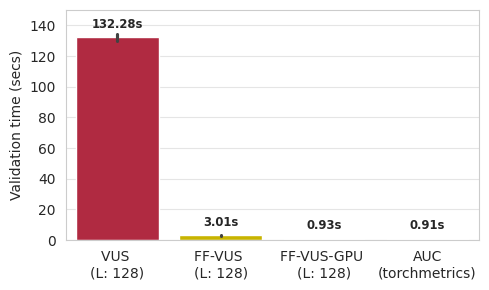

In [15]:
fig, axes = plt.subplots(1, 1, figsize=(5, 3))
df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Val time'] = df_plot['Val time'].astype(float)

sns.barplot(
    data=df_plot,
    x='Metric',
    y='Val time',
    hue='Metric',
    palette=color_palette,
    ax=axes,
    saturation=1,
)
# axes.set_title('Validation Time per Epoch')
print('Validation Time per Epoch')
axes.set_ylabel('Validation time (secs)')
axes.set_xlabel('')
axes.tick_params(axis='x', rotation=0)
axes.grid(axis='y', alpha=0.5)
axes.set_ylim(0, 150)

# Add mean validation times on top of each bar
mean_val_times = df_plot.groupby('Metric')['Val time'].mean()
for i, metric in enumerate(axes.get_xticklabels()):
    metric_name = metric.get_text()
    mean_time = mean_val_times.get(metric_name, 0)
    axes.text(i, mean_time + 4.2, f'{mean_time:.2f}s', ha='center', va='bottom', fontsize='small', fontweight='bold')

# Add '(torchmetrics)' below 'AUC' label
xticklabels = axes.get_xticklabels()
for label in xticklabels:
    if label.get_text() == 'AUC':
        label.set_text('AUC(torchmetrics)')
    if '(' in label.get_text():
        label.set_text(label.get_text().replace('(', '\n('))
axes.set_xticks(np.arange(4), xticklabels)

finalize_plot(save_fig_path, 'msad_pipeline_validation_overhead_barplot')

In [16]:
print("FF-VUS metrics add minimal overhead\nwhile providing advanced evaluation")
df_plot.groupby('Metric')['Val time'].mean()

FF-VUS metrics add minimal overhead
while providing advanced evaluation


Metric
AUC                      0.907832
FF-VUS (L: 128)          3.014070
FF-VUS-GPU (L: 128)      0.929918
VUS (L: 128)           132.284974
Name: Val time, dtype: float64

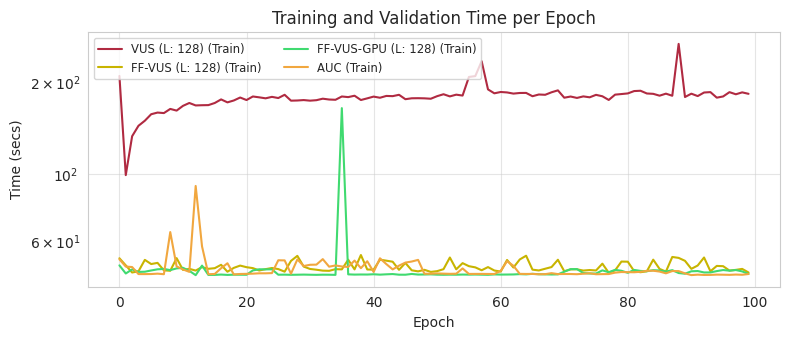

In [169]:
fig, axis = plt.subplots(1, 1, figsize=(8, 3.5))

df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Train time'] = df_plot['Train time'].astype(float)
df_plot['Val time'] = df_plot['Val time'].astype(float)
df_plot['Epoch'] = df_plot['Epoch'].astype(int)

for metric in df_plot['Metric'].unique():
    metric_data = df_plot[df_plot['Metric'] == metric].sort_values('Epoch')
    color = color_palette[metric]
    
    # Solid line for validation time
    # axis.plot(metric_data['Epoch'], metric_data['Val time'], 
    #           color=color, linewidth=2, marker='o', label=f'{metric} (Val)', linestyle='-')
    
    # # Dotted line for training time
    # axis.plot(metric_data['Epoch'], metric_data['Train time'], 
    #           color=color, linewidth=2, marker='s', label=f'{metric} (Train)', linestyle='dotted')

    # Dashed line for total time
    sns.lineplot(data=metric_data, x='Epoch', y=metric_data['Total time'], color=color, linewidth=1.5, label=f'{metric} (Train)', linestyle='solid', ax=axis)

    # axis.plot(metric_data['Epoch'], metric_data['Total time'].rolling(window=20, min_periods=1).mean(), 
    #           color=color, linewidth=1.5, label=f'{metric}', linestyle='solid')
axis.set_xlabel('Epoch')
axis.set_ylabel('Time (secs)')
axis.set_title('Training and Validation Time per Epoch')
axis.grid(axis='both', alpha=0.5)
axis.legend(ncol=2, fontsize='small', loc='upper left')
axis.set_yscale('log')


finalize_plot(save_fig_path, 'training_validation_time_per_epoch')

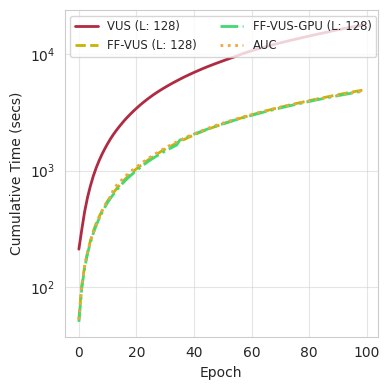

In [190]:
fig, axis = plt.subplots(1, 1, figsize=(4, 4))

df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Train time'] = df_plot['Train time'].astype(float)
df_plot['Val time'] = df_plot['Val time'].astype(float)
df_plot['Epoch'] = df_plot['Epoch'].astype(int)

for metric in df_plot['Metric'].unique():
    metric_data = df_plot[df_plot['Metric'] == metric].sort_values('Epoch')
    # Calculate cumulative times
    metric_data = metric_data.copy()
    metric_data['Train time'] = metric_data['Train time'].cumsum()
    metric_data['Val time'] = metric_data['Val time'].cumsum()
    
    color = color_palette[metric]
    
    # Solid line for validation time
    # axis.plot(metric_data['Epoch'], metric_data['Val time'], 
    #           color=color, linewidth=2, label=f'{metric} (Val)', linestyle='-')
    
    # # Dotted line for training time
    # axis.plot(metric_data['Epoch'], metric_data['Train time'], 
    #           color=color, linewidth=4, label=f'{metric} (Train)', linestyle='dotted')
    
    # Total time with different line styles for each metric
    linestyles = {
        'VUS (L: 128)': '-',
        'FF-VUS (L: 128)': '--',
        'FF-VUS-GPU (L: 128)': '-.',
        'AUC': ':'
    }
    axis.plot(metric_data['Epoch'], metric_data['Train time'] + metric_data['Val time'], 
        color=color, linewidth=2, label=f'{metric}', linestyle=linestyles.get(metric, '-'))

axis.set_xlabel('Epoch')
axis.set_ylabel('Cumulative Time (secs)')
# axis.set_title('Cumulative Training and Validation Time per Epoch')
axis.grid(axis='both', alpha=0.5)
axis.legend(ncol=2, fontsize='small', loc='upper left')
axis.set_yscale('log')


finalize_plot(save_fig_path, 'cumulative_time_time_per_epoch')

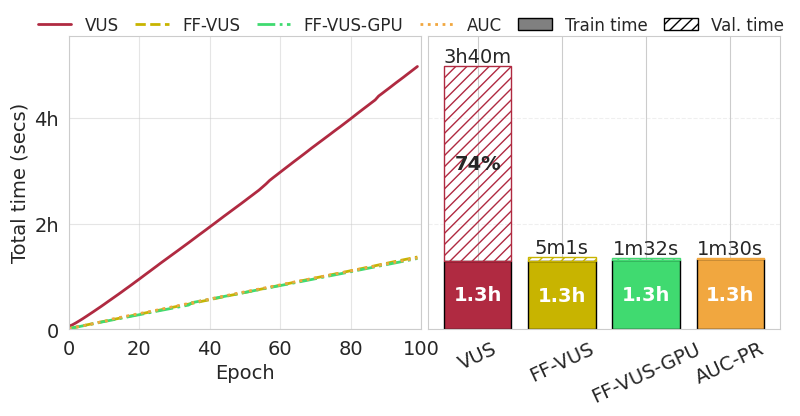

Figure X: Training time comparison for MSAD model selection. (Left) Cumulative training time across 100 epochs showing VUS validation overhead dominates total runtime. (Right) Stacked bar chart decomposing total training time into training (solid) and validation (hatched) components. VUS incurs ~74% validation overhead, while FF-VUS-GPU achieves comparable evaluation quality with <2% overhead, matching AUC-PR efficiency.


In [333]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)


ax = axes[1]
train_times = grouped_sorted['Train time'].values
val_times = grouped_sorted['Val time'].values
x_pos = np.arange(len(grouped_sorted))

# Create stacked bars
bars1 = ax.bar(x_pos, train_times, color=[color_palette[m] for m in grouped_sorted['Metric']], edgecolor='black', label='Training (bottom part)')
bars2 = ax.bar(x_pos, val_times, bottom=train_times, color='none', edgecolor=[color_palette[m] for m in grouped_sorted['Metric']], hatch='///', linewidth=1, label='Validation (top part)')

ax.set_xticks(x_pos)
ax.set_xticklabels([metric_labels[m] for m in grouped_sorted['Metric']], rotation=25, fontsize=14) # + ('\n(L: 512)' if 'VUS' in m else '')
legend_handles = [
    Patch(facecolor='black', edgecolor='black', label='Train time'),
    Patch(facecolor='none', edgecolor='black', hatch='///', linewidth=1, label='Validation time')
]
ax.legend(handles=legend_handles, loc='upper right', framealpha=0.95)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add total time labels on top
for i, (val, total) in enumerate(zip(val_times, grouped_sorted['Total time'])):
    if val >= 3600:
        hrs = int(val // 3600)
        mins = int((val % 3600) // 60)
        ax.text(i, total + 3, f'{hrs}h{mins}m', ha='center', va='bottom', size=14)
    elif val >= 60:
        ax.text(i, total + 3, f'{int(val // 60)}m{int(val % 60)}s', ha='center', va='bottom', size=14)
    else:
        ax.text(i, total + 3, f'{val:.1f}s', ha='center', va='bottom', size=14)

# Add validation overhead percentage labels on the orange section
for i, (train, val, total) in enumerate(zip(train_times, val_times, grouped_sorted['Total time'])):
    val_pct = (val/(train+val)) * 100
    hrs = int(train // 3600)
    mins = int((train % 3600) // 60)
    # ax.text(i, train/2, f'{hrs}h{mins}m', ha='center', va='center', weight='bold', color='white')
    ax.text(i, train/2, f'{train/3600:.1f}h', ha='center', va='center', weight='bold', color='white', size=14)

    if val_pct > 8:
        ax.text(i, train + val/2, f'{val_pct:.0f}%', ha='center', va='center', weight='bold', size=14)

# ---------------------------
axis = axes[0]

df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Epoch'] = df_plot['Epoch'].astype(int)

for metric in df_plot['Metric'].unique():
    metric_data = df_plot[df_plot['Metric'] == metric].sort_values('Epoch')

    metric_data = metric_data.copy()
    metric_data['Train time'] = metric_data['Train time'].cumsum()
    metric_data['Val time'] = metric_data['Val time'].cumsum()
    
    color = color_palette[metric]
    linestyles = {
        'VUS (L: 128)': '-',
        'FF-VUS (L: 128)': '--',
        'FF-VUS-GPU (L: 128)': '-.',
        'AUC': ':'
    }
    axis.plot(metric_data['Epoch'], metric_data['Train time'] + metric_data['Val time'], 
        color=color, linewidth=2, label=f'{metric}', linestyle=linestyles.get(metric, '-'))

axis.set_xlabel('Epoch', size=14)
axis.set_ylabel('Total time (secs)', size=14)
axis.set_xticks(ticks=axis.get_xticks(), labels=axis.get_xticklabels(), fontsize=14)
axis.set_yticks(ticks=[0, 7200, 14400], labels=['0', '2h', '4h'], fontsize=14)
axis.set_ylim(0, 20000)
axis.grid(axis='both', alpha=0.5)
# axis.legend(ncol=2, fontsize='small', loc='upper left')
axis.set_xlim(0, 100)

handles, labels = axis.get_legend_handles_labels()
handles += [
    Patch(facecolor='gray', edgecolor='black', label='Train time'),
    Patch(facecolor='none', edgecolor='black', hatch='///', linewidth=1, label='Validation time')
]
labels += ['Train time', 'Val. time']
labels = [label.replace(' (L: 128)', '').replace(' mean', '') for label in labels]
ax.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.52, 1.05),
    ncol=len(labels),
    frameon=False,
    fontsize='large',
    columnspacing=1.0
)

plt.tight_layout()
fig.subplots_adjust(wspace=0.02)
save_path = os.path.join(save_fig_path, 'toy_example_combined')
plt.savefig(f"{save_path}.pdf", bbox_inches='tight', pad_inches=0)
plt.show()

print("Figure X: Training time comparison for MSAD model selection. (Left) Cumulative training time across 100 epochs showing VUS validation overhead dominates total runtime. (Right) Stacked bar chart decomposing total training time into training (solid) and validation (hatched) components. VUS incurs ~74% validation overhead, while FF-VUS-GPU achieves comparable evaluation quality with <2% overhead, matching AUC-PR efficiency.")

In [330]:
df_plot = df[df['Epoch'] != 'TOTAL'].copy()

grouped = df_plot.groupby('Metric')[['Train time', 'Val time', 'Total time']].sum().reset_index()
metric_order = ['VUS (L: 128)', 'FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)', 'AUC']
# metric_order = ['FF-VUS (L: 128)', 'FF-VUS-GPU (L: 128)', 'AUC']
grouped_sorted = grouped.set_index('Metric').loc[metric_order].reset_index()
# Print grouped_sorted with times in appropriate units
for _, row in grouped_sorted.iterrows():
    metric = row['Metric']
    train_secs = row['Train time']
    val_secs = row['Val time']
    total_secs = row['Total time']
    
    def format_time(secs):
        if secs >= 3600:
            return f"{secs/3600:.0f}h{((secs%3600)/60):.0f}m"
        elif secs >= 60:
            return f"{secs/60:.1f}m"
        else:
            return f"{secs:.1f}s"
    
    print(f"{metric}: Train={format_time(train_secs)}, Val={format_time(val_secs)}, Total={format_time(total_secs)}")

grouped_sorted

VUS (L: 128): Train=1h18m, Val=4h40m, Total=5h59m
FF-VUS (L: 128): Train=1h17m, Val=5.0m, Total=1h22m
FF-VUS-GPU (L: 128): Train=1h19m, Val=1.5m, Total=1h21m
AUC: Train=1h20m, Val=1.5m, Total=1h21m


,Metric,Train time,Val time,Total time
0,VUS (L: 128),4692.285551,13228.497365,17920.782916
1,FF-VUS (L: 128),4630.477214,301.407007,4931.884221
2,FF-VUS-GPU (L: 128),4737.914083,92.991771,4830.905854
3,AUC,4774.420968,90.783151,4865.204119


## Experiment: Compare existence algorithms


In [12]:
curr_experiment_path = os.path.join(experiments_path, 'existence_comparison')
existence_df = pd.read_csv(os.path.join(curr_experiment_path, 'tsb_all_128.csv'))

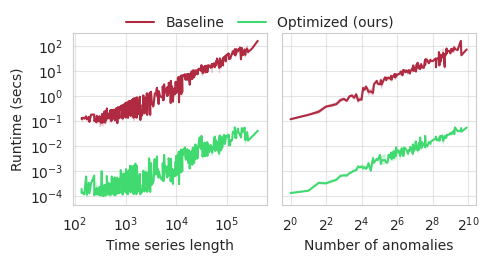

In [45]:

fig, axes = plt.subplots(1, 2, figsize=(5, 2.5), sharey=True)

ax = axes[0]
# existence_df_sorted = existence_df.sort_values('T')
# existence_df_smooth = existence_df_sorted.rolling(1).mean()

sns.lineplot(data=existence_df, x='T', y='trivial_mean', label='Baseline', color='#b02a41', ax=ax)
sns.lineplot(data=existence_df, x='T', y='optimized_mean', label='Optimized (ours)', color='#40da70', ax=ax)
ax.set_xlabel('Time series length')
ax.set_ylabel('Runtime (secs)')
ax.set_yscale('log')
ax.set_xscale('log', base=10)
ax.grid(axis='both', alpha=0.5)
ax.legend().remove()
ax.set_yticks([10**x for x in range(-4, 3)])
ax.set_xticks([10**x for x in range(2, 6)])

ax = axes[1]
existence_df_sorted = existence_df.sort_values('n_anomalies')
sns.lineplot(data=existence_df, x='n_anomalies', y='trivial_mean', label='Baseline', color='#b02a41', ax=ax)
sns.lineplot(data=existence_df, x='n_anomalies', y='optimized_mean', label='Optimized (ours)', color='#40da70', ax=ax)
ax.set_xlabel('Number of anomalies')
ax.set_ylabel('')
ax.set_yscale('log')
ax.grid(axis='both', alpha=0.5)
ax.set_xscale('log', base=2)
ax.set_yticks([10**x for x in range(-4, 3)])
# ax.set_xticks([2**x for x in range(0, 11, 2)], [2**x for x in range(0, 11, 2)])
ax.set_xticks([2**x for x in range(0, 11, 2)])

handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.53, 1.06),
    ncol=len(labels),
    frameon=False,
    fontsize='medium',
    columnspacing=1.0
)

finalize_plot(save_fig_path, 'existence_comparison')

In [46]:
# Analyze speedup of optimized existence algorithm over trivial implementation
print("="*70)
print("EXISTENCE ALGORITHM OPTIMIZATION ANALYSIS")
print("="*70)

# Overall statistics
print("\nOVERALL SPEEDUP:")
print(f"  Mean speedup: {existence_df['speedup'].mean():.1f}×")
print(f"  Median speedup: {existence_df['speedup'].median():.1f}×")
print(f"  Min speedup: {existence_df['speedup'].min():.1f}×")
print(f"  Max speedup: {existence_df['speedup'].max():.1f}×")

# Speedup by time series length
print("\nSPEEDUP BY TIME SERIES LENGTH:")
length_groups = existence_df.groupby(pd.cut(existence_df['T'], bins=5))
for interval, group in length_groups:
    print(f"  Length {interval}: {group['speedup'].mean():.1f}× (n={len(group)})")

# Speedup by number of anomalies
print("\nSPEEDUP BY NUMBER OF ANOMALIES:")
anomaly_groups = existence_df.groupby('n_anomalies')
for n_anom, group in anomaly_groups:
    print(f"  {n_anom} anomalies: {group['speedup'].mean():.1f}× (n={len(group)})")

# Absolute time comparison
print("\nABSOLUTE TIMING:")
print(f"  Trivial implementation:")
print(f"    Mean time: {existence_df['trivial_mean'].mean():.4f}s")
print(f"    Max time:  {existence_df['trivial_mean'].max():.4f}s")
print(f"  Optimized implementation:")
print(f"    Mean time: {existence_df['optimized_mean'].mean():.6f}s")
print(f"    Max time:  {existence_df['optimized_mean'].max():.6f}s")

# Correctness verification
print("\nCORRECTNESS VERIFICATION:")
print(f"  All results match: {existence_df['matches'].all()}")
print(f"  Max difference: {existence_df['max_diff'].max():.2e}")
print(f"  Mean difference: {existence_df['mean_diff'].mean():.2e}")

# Large-scale problem analysis
print("\nLARGE-SCALE PROBLEMS (>100k time series length):")
large_scale = existence_df[existence_df['T'] > 100000]
if len(large_scale) > 0:
    print(f"  Number of problems: {len(large_scale)}")
    print(f"  Mean speedup: {large_scale['speedup'].mean():.1f}×")
    print(f"  Trivial time: {large_scale['trivial_mean'].mean():.2f}s")
    print(f"  Optimized time: {large_scale['optimized_mean'].mean():.4f}s")

print("\n" + "="*70)

EXISTENCE ALGORITHM OPTIMIZATION ANALYSIS

OVERALL SPEEDUP:
  Mean speedup: 1157.7×
  Median speedup: 1120.2×
  Min speedup: 25.7×
  Max speedup: 4177.5×

SPEEDUP BY TIME SERIES LENGTH:
  Length (-267.737, 80883.4]: 1125.3× (n=1971)
  Length (80883.4, 161630.8]: 1936.4× (n=45)
  Length (161630.8, 242378.2]: 2034.4× (n=16)
  Length (242378.2, 323125.6]: 2998.1× (n=5)
  Length (323125.6, 403873.0]: 4016.0× (n=2)

SPEEDUP BY NUMBER OF ANOMALIES:
  1 anomalies: 949.6× (n=508)
  2 anomalies: 1136.3× (n=556)
  3 anomalies: 803.3× (n=117)
  4 anomalies: 1233.5× (n=65)
  5 anomalies: 1223.2× (n=50)
  6 anomalies: 1134.3× (n=59)
  7 anomalies: 1114.4× (n=28)
  8 anomalies: 1212.0× (n=35)
  9 anomalies: 1076.1× (n=27)
  10 anomalies: 1248.2× (n=65)
  11 anomalies: 1231.5× (n=38)
  12 anomalies: 955.5× (n=29)
  13 anomalies: 1210.0× (n=51)
  14 anomalies: 485.9× (n=16)
  15 anomalies: 582.5× (n=17)
  16 anomalies: 472.1× (n=14)
  17 anomalies: 1732.8× (n=3)
  18 anomalies: 1234.6× (n=2)
  19 anom

/tmp/ipykernel_7625/895005727.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  length_groups = existence_df.groupby(pd.cut(existence_df['T'], bins=5))
